<a href="https://colab.research.google.com/github/chervov/ProteinModelling1/blob/main/JAK2_centroids.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JAK2 - open-close

For AF2 and Shan's structure compute the centroids for JH1 and JH2

and the difference

Shan's stucture is AF2 closed form candidate



In [1]:
%pip install -q requests biopython numpy pandas

import io
from pathlib import Path

import requests
import numpy as np
import pandas as pd

from Bio.PDB import PDBParser, PDBIO, Superimposer
from Bio.Align import PairwiseAligner
from Bio.SeqUtils import seq1
from IPython.display import display

UNIPROT_ID = "O60674"  # Human JAK2

SHAN_URL = (
    "https://raw.githubusercontent.com/chervov/ProteinModelling1/main/"
    "Shan2014JAK1JAK2/"
    "NIHMS704086-supplement-PDB_coordinates_for_JAK2_model.pdb"
)

OUTPUT_DIR = Path("/content/JAK2_comparison")
OUTPUT_DIR.mkdir(exist_ok=True)


def get_json(url):
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    return response.json()


def get_text(url):
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    return response.text


def print_sequence(title, sequence):
    print(f"\n>{title}")
    for start in range(0, len(sequence), 80):
        print(sequence[start:start + 80])
    print(f"Length: {len(sequence)} amino acids")


# ============================================================
# 1. UniProt reference sequence and domain boundaries
# ============================================================
uniprot = get_json(
    f"https://rest.uniprot.org/uniprotkb/{UNIPROT_ID}.json"
)
reference_sequence = uniprot["sequence"]["value"]

print(f"Protein: {uniprot['uniProtkbId']}")
print(f"UniProt ID: {UNIPROT_ID}")
print(f"https://www.uniprot.org/uniprotkb/{UNIPROT_ID}/entry")

print_sequence("JAK2 UniProt canonical sequence", reference_sequence)

domain_names = {
    "FERM": "FERM",
    "SH2": "SH2",
    "Protein kinase 1": "JH2",
    "Protein kinase 2": "JH1",
}

domain_rows = []
domain_ranges = {}

for feature in uniprot.get("features", []):
    if feature["type"] != "Domain":
        continue

    description = feature.get("description", "Domain")
    name = domain_names.get(description, description)
    start = int(feature["location"]["start"]["value"])
    end = int(feature["location"]["end"]["value"])

    domain_rows.append({
        "Domain": name,
        "UniProt annotation": description,
        "Start": start,
        "End": end,
        "Length": end - start + 1,
    })
    domain_ranges[name] = [[start, end]]

if not {"JH1", "JH2"}.issubset(domain_ranges):
    raise ValueError("Could not identify JH1 and JH2 in UniProt.")

print("\nUniProt domains: 1-based coordinates, inclusive endpoints")
display(pd.DataFrame(domain_rows))


# ============================================================
# 2. Download AlphaFold and Shan structures
# ============================================================
predictions = get_json(
    f"https://alphafold.ebi.ac.uk/api/prediction/{UNIPROT_ID}"
)

full_length_models = [
    model for model in predictions
    if int(model.get("uniprotStart", -1)) == 1
    and int(model.get("uniprotEnd", -1)) == len(reference_sequence)
    and model.get("pdbUrl")
]

if not full_length_models:
    raise ValueError("No full-length AlphaFold JAK2 PDB found.")

af_url = full_length_models[0]["pdbUrl"]
af_text = get_text(af_url)
shan_text = get_text(SHAN_URL)

af_path = OUTPUT_DIR / "AF_JAK2.pdb"
shan_path = OUTPUT_DIR / "Shan_JAK2_original.pdb"

af_path.write_text(af_text)
shan_path.write_text(shan_text)

print(f"\nAlphaFold URL: {af_url}")
print(f"Shan URL: {SHAN_URL}")

parser = PDBParser(QUIET=True)
af_structure = parser.get_structure("AF", io.StringIO(af_text))
shan_structure = parser.get_structure("Shan", io.StringIO(shan_text))


# ============================================================
# 3. Map each modeled sequence to full-length UniProt numbering
#    Necessary for Shan's JH2–JH1 fragment.
# ============================================================
aligner = PairwiseAligner()
aligner.mode = "global"
aligner.match_score = 2
aligner.mismatch_score = -1
aligner.open_gap_score = -8
aligner.extend_gap_score = -0.5

# Do not penalize unmodeled reference termini.
aligner.query_left_gap_score = 0
aligner.query_right_gap_score = 0


def map_structure_to_uniprot(structure):
    candidates = []

    # Use the first structural model.
    for chain in next(structure.get_models()):
        residues = [
            residue for residue in chain
            if residue.id[0] == " "
        ]
        if not residues:
            continue

        sequence = "".join(
            seq1(residue.resname, undef_code="X")
            for residue in residues
        )

        alignment = aligner.align(reference_sequence, sequence)[0]
        mapping = {}
        matches = 0

        for ref_block, query_block in zip(
            alignment.aligned[0], alignment.aligned[1]
        ):
            ref_start, ref_end = map(int, ref_block)
            query_start, query_end = map(int, query_block)

            for ref_index, query_index in zip(
                range(ref_start, ref_end),
                range(query_start, query_end),
            ):
                # Key = full-length UniProt position.
                mapping[ref_index + 1] = residues[query_index]
                matches += (
                    reference_sequence[ref_index] == sequence[query_index]
                )

        candidates.append({
            "chain": chain.id,
            "sequence": sequence,
            "mapping": mapping,
            "matches": matches,
            "identity": matches / len(mapping) if mapping else 0.0,
        })

    if not candidates:
        raise ValueError("No protein chain found.")

    best = max(candidates, key=lambda model: model["matches"])

    if best["identity"] < 0.90:
        raise ValueError(
            f"Low sequence identity to JAK2: {best['identity']:.2%}"
        )

    return best


af = map_structure_to_uniprot(af_structure)
shan = map_structure_to_uniprot(shan_structure)

for name, model in (("AlphaFold JAK2", af), ("Shan JAK2", shan)):
    print_sequence(
        f"{name} | {UNIPROT_ID} | chain {model['chain']!r}",
        model["sequence"],
    )
    print(f"Identity to UniProt: {model['identity']:.2%}")
    print(
        f"Mapped UniProt span: "
        f"{min(model['mapping'])}–{max(model['mapping'])}"
    )


# ============================================================
# 4. Align Shan onto AlphaFold using corresponding JH2/JH1 Cα
# ============================================================
def in_kinase_domains(position):
    return any(
        start <= position <= end
        for domain in ("JH2", "JH1")
        for start, end in domain_ranges[domain]
    )


paired_positions = [
    position
    for position in sorted(set(af["mapping"]) & set(shan["mapping"]))
    if in_kinase_domains(position)
    and "CA" in af["mapping"][position]
    and "CA" in shan["mapping"][position]
]

if len(paired_positions) < 3:
    raise ValueError("Too few corresponding Cα atoms for alignment.")

fixed_atoms = [af["mapping"][p]["CA"] for p in paired_positions]
moving_atoms = [shan["mapping"][p]["CA"] for p in paired_positions]

superimposer = Superimposer()
superimposer.set_atoms(fixed_atoms, moving_atoms)
superimposer.apply(list(shan_structure.get_atoms()))

print(
    f"\nShan → AlphaFold combined JH2/JH1 alignment:"
    f"\n  Cα pairs: {len(paired_positions)}"
    f"\n  RMSD: {superimposer.rms:.3f} Å"
)

aligned_path = OUTPUT_DIR / "Shan_JAK2_aligned_to_AF.pdb"
writer = PDBIO()
writer.set_structure(shan_structure)
writer.save(str(aligned_path))
print(f"Aligned Shan model saved: {aligned_path}")


# ============================================================
# 5. Orianne's centroid calculation
#    Same averaging and Euclidean-distance formula.
#    Coordinates are indexed by mapped UniProt position.
# ============================================================
def _centroid_for_ranges(coords_by_resseq, ranges):
    points = []
    for start, end in ranges:
        for r in range(int(start), int(end) + 1):
            if r in coords_by_resseq:
                points.append(coords_by_resseq[r])

    if not points:
        raise ValueError("No CA atoms found for requested residue ranges")

    pts = np.stack(points, axis=0)
    return np.mean(pts, axis=0)


coordinates = {
    name: {
        position: np.asarray(residue["CA"].coord, dtype=np.float64)
        for position, residue in model["mapping"].items()
        if "CA" in residue
    }
    for name, model in (("AlphaFold", af), ("Shan", shan))
}

centroid_rows = []
comparison_rows = []

for name, coords in coordinates.items():
    centroids = {}
    counts = {}

    print(f"\n{'=' * 60}\n{name} JAK2")

    for domain in ("JH2", "JH1"):
        ranges = domain_ranges[domain]
        centroids[domain] = _centroid_for_ranges(coords, ranges)

        expected = [
            r
            for start, end in ranges
            for r in range(start, end + 1)
        ]
        present = [r for r in expected if r in coords]
        missing = [r for r in expected if r not in coords]
        counts[domain] = len(present)

        center = centroids[domain]
        print(
            f"{domain} centroid (Å): "
            f"x={center[0]:.3f}, y={center[1]:.3f}, z={center[2]:.3f}"
        )
        print(f"  Cα coverage: {len(present)}/{len(expected)}")
        if missing:
            print(f"  Missing UniProt positions: {missing}")

        centroid_rows.append({
            "Model": name,
            "Domain": domain,
            "CA_count": len(present),
            "X_A": center[0],
            "Y_A": center[1],
            "Z_A": center[2],
        })

    delta = centroids["JH1"] - centroids["JH2"]
    distance = float(np.linalg.norm(delta))

    print(f"JH1 − JH2 vector (Å): {np.round(delta, 3)}")
    print(f"JH2–JH1 centroid distance: {distance:.3f} Å")

    comparison_rows.append({
        "Model": name,
        "JH2_CA_count": counts["JH2"],
        "JH1_CA_count": counts["JH1"],
        "Delta_X_A": delta[0],
        "Delta_Y_A": delta[1],
        "Delta_Z_A": delta[2],
        "Distance_A": distance,
    })

print("\nCentroid coordinates:")
centroid_table = pd.DataFrame(centroid_rows)
display(centroid_table.round(3))

print("\nCentroid differences and distances:")
distance_table = pd.DataFrame(comparison_rows).set_index("Model")
display(distance_table.round(3))

difference = (
    distance_table.loc["AlphaFold", "Distance_A"]
    - distance_table.loc["Shan", "Distance_A"]
)
print(f"\nAlphaFold minus Shan centroid distance: {difference:+.3f} Å")


# ============================================================
# 6. Additional comparison using identical residue sets
#    Prevent missing residues from affecting comparability.
# ============================================================
common_positions = set(coordinates["AlphaFold"]) & set(coordinates["Shan"])
common_rows = []

for name, coords in coordinates.items():
    common_coords = {
        position: xyz
        for position, xyz in coords.items()
        if position in common_positions
    }

    c_jh2 = _centroid_for_ranges(common_coords, domain_ranges["JH2"])
    c_jh1 = _centroid_for_ranges(common_coords, domain_ranges["JH1"])

    row = {"Model": name}
    for domain in ("JH2", "JH1"):
        row[f"{domain}_CA_count"] = sum(
            r in common_coords
            for start, end in domain_ranges[domain]
            for r in range(start, end + 1)
        )
    row["Distance_A"] = float(np.linalg.norm(c_jh1 - c_jh2))
    common_rows.append(row)

print("\nComparison using exactly the same domain residues in both models:")
display(pd.DataFrame(common_rows).set_index("Model").round(3))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 10.5 MB/s eta 0:00:00
Protein: JAK2_HUMAN
UniProt ID: O60674
https://www.uniprot.org/uniprotkb/O60674/entry

>JAK2 UniProt canonical sequence
MGMACLTMTEMEGTSTSSIYQNGDISGNANSMKQIDPVLQVYLYHSLGKSEADYLTFPSGEYVAEEICIAASKACGITPV
YHNMFALMSETERIWYPPNHVFHIDESTRHNVLYRIRFYFPRWYCSGSNRAYRHGISRGAEAPLLDDFVMSYLFAQWRHD
FVHGWIKVPVTHETQEECLGMAVLDMMRIAKENDQTPLAIYNSISYKTFLPKCIRAKIQDYHILTRKRIRYRFRRFIQQF
SQCKATARNLKLKYLINLETLQSAFYTEKFEVKEPGSGPSGEEIFATIIITGNGGIQWSRGKHKESETLTEQDLQLYCDF
PNIIDVSIKQANQEGSNESRVVTIHKQDGKNLEIELSSLREALSFVSLIDGYYRLTADAHHYLCKEVAPPAVLENIQSNC
HGPISMDFAISKLKKAGNQTGLYVLRCSPKDFNKYFLTFAVERENVIEYKHCLITKNENEEYNLSGTKKNFSSLKDLLNC
YQMETVRSDNIIFQFTKCCPPKPKDKSNLLVFRTNGVSDVPTSPTLQRPTHMNQMVFHKIRNEDLIFNESLGQGTFTKIF
KGVRREVGDYGQLHETEVLLKVLDKAHRNYSESFFEAASMMSKLSHKHLVLNYGVCVCGDENILVQEFVKFGSLDTYLKK
NKNCINILWKLEVAKQLAWAMHFLEENTLIHGNVCAKNILLIREEDRKTGNPPFIKLSDPGISITVLPKDILQERIPWVP
PECIENPKNLNLATDKWSFGTTLWEICSGGDKPLSALDSQRKLQFYEDRHQLPAPKWAELANLINNCMDYEPDF

,Domain,UniProt annotation,Start,End,Length
0,FERM,FERM,37,380,344
1,SH2; atypical,SH2; atypical,401,482,82
2,JH2,Protein kinase 1,545,809,265
3,JH1,Protein kinase 2,849,1124,276



AlphaFold URL: https://alphafold.ebi.ac.uk/files/AF-O60674-F1-model_v6.pdb
Shan URL: https://raw.githubusercontent.com/chervov/ProteinModelling1/main/Shan2014JAK1JAK2/NIHMS704086-supplement-PDB_coordinates_for_JAK2_model.pdb

>AlphaFold JAK2 | O60674 | chain 'A'
MGMACLTMTEMEGTSTSSIYQNGDISGNANSMKQIDPVLQVYLYHSLGKSEADYLTFPSGEYVAEEICIAASKACGITPV
YHNMFALMSETERIWYPPNHVFHIDESTRHNVLYRIRFYFPRWYCSGSNRAYRHGISRGAEAPLLDDFVMSYLFAQWRHD
FVHGWIKVPVTHETQEECLGMAVLDMMRIAKENDQTPLAIYNSISYKTFLPKCIRAKIQDYHILTRKRIRYRFRRFIQQF
SQCKATARNLKLKYLINLETLQSAFYTEKFEVKEPGSGPSGEEIFATIIITGNGGIQWSRGKHKESETLTEQDLQLYCDF
PNIIDVSIKQANQEGSNESRVVTIHKQDGKNLEIELSSLREALSFVSLIDGYYRLTADAHHYLCKEVAPPAVLENIQSNC
HGPISMDFAISKLKKAGNQTGLYVLRCSPKDFNKYFLTFAVERENVIEYKHCLITKNENEEYNLSGTKKNFSSLKDLLNC
YQMETVRSDNIIFQFTKCCPPKPKDKSNLLVFRTNGVSDVPTSPTLQRPTHMNQMVFHKIRNEDLIFNESLGQGTFTKIF
KGVRREVGDYGQLHETEVLLKVLDKAHRNYSESFFEAASMMSKLSHKHLVLNYGVCVCGDENILVQEFVKFGSLDTYLKK
NKNCINILWKLEVAKQLAWAMHFLEENTLIHGNVCAKNILLIREEDRKTGNPPFIKLSDPGISITVLPKDILQERIPWVP
PECIENP

/usr/local/lib/python3.13/dist-packages/Bio/Align/__init__.py:4412: BiopythonDeprecationWarning: The attribute 'query_left_gap_score' was renamed to 'left_deletion_score'. This was done to be consistent with the
AlignmentCounts object returned by the .counts method of an Alignment object.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/Bio/Align/__init__.py:4412: BiopythonDeprecationWarning: The attribute 'query_right_gap_score' was renamed to 'right_deletion_score'. This was done to be consistent with the
AlignmentCounts object returned by the .counts method of an Alignment object.
  warnings.warn(


,Model,Domain,CA_count,X_A,Y_A,Z_A
0,AlphaFold,JH2,265,3.300,2.201,-6.979
1,AlphaFold,JH1,276,39.040,9.630,-34.811
2,Shan,JH2,265,5.235,8.380,-8.387
3,Shan,JH1,276,37.182,3.697,-33.460



Centroid differences and distances:


,JH2_CA_count,JH1_CA_count,Delta_X_A,Delta_Y_A,Delta_Z_A,Distance_A
Model,,,,,,
AlphaFold,265,276,35.740,7.429,-27.832,45.904
Shan,265,276,31.947,-4.683,-25.073,40.880



AlphaFold minus Shan centroid distance: +5.023 Å

Comparison using exactly the same domain residues in both models:


,JH2_CA_count,JH1_CA_count,Distance_A
Model,,,
AlphaFold,265,276,45.904
Shan,265,276,40.880


For the reference:


| Object or distance | Typical scale |
|---|---:|
| C–C or C–N covalent bond length | **1.3–1.5 Å** |
| Carbon atom diameter, using its van der Waals size | **≈3.4 Å** |
| Distance between successive backbone Cα atoms | **≈3.8 Å** |
| Diameter of a compact kinase domain | **Several tens of Å** |

| RMSD | Interpretation for a well-matched compact domain |
|---|---|
| **<1 Å** | Very close |
| **1–2 Å** | Close, with noticeable local differences |
| **2–3 Å** | Substantial differences |
| **>3–5 Å** | Large differences requiring inspection |




# Plots AF2 and Shan


AlphaFold JAK2 — entire protein


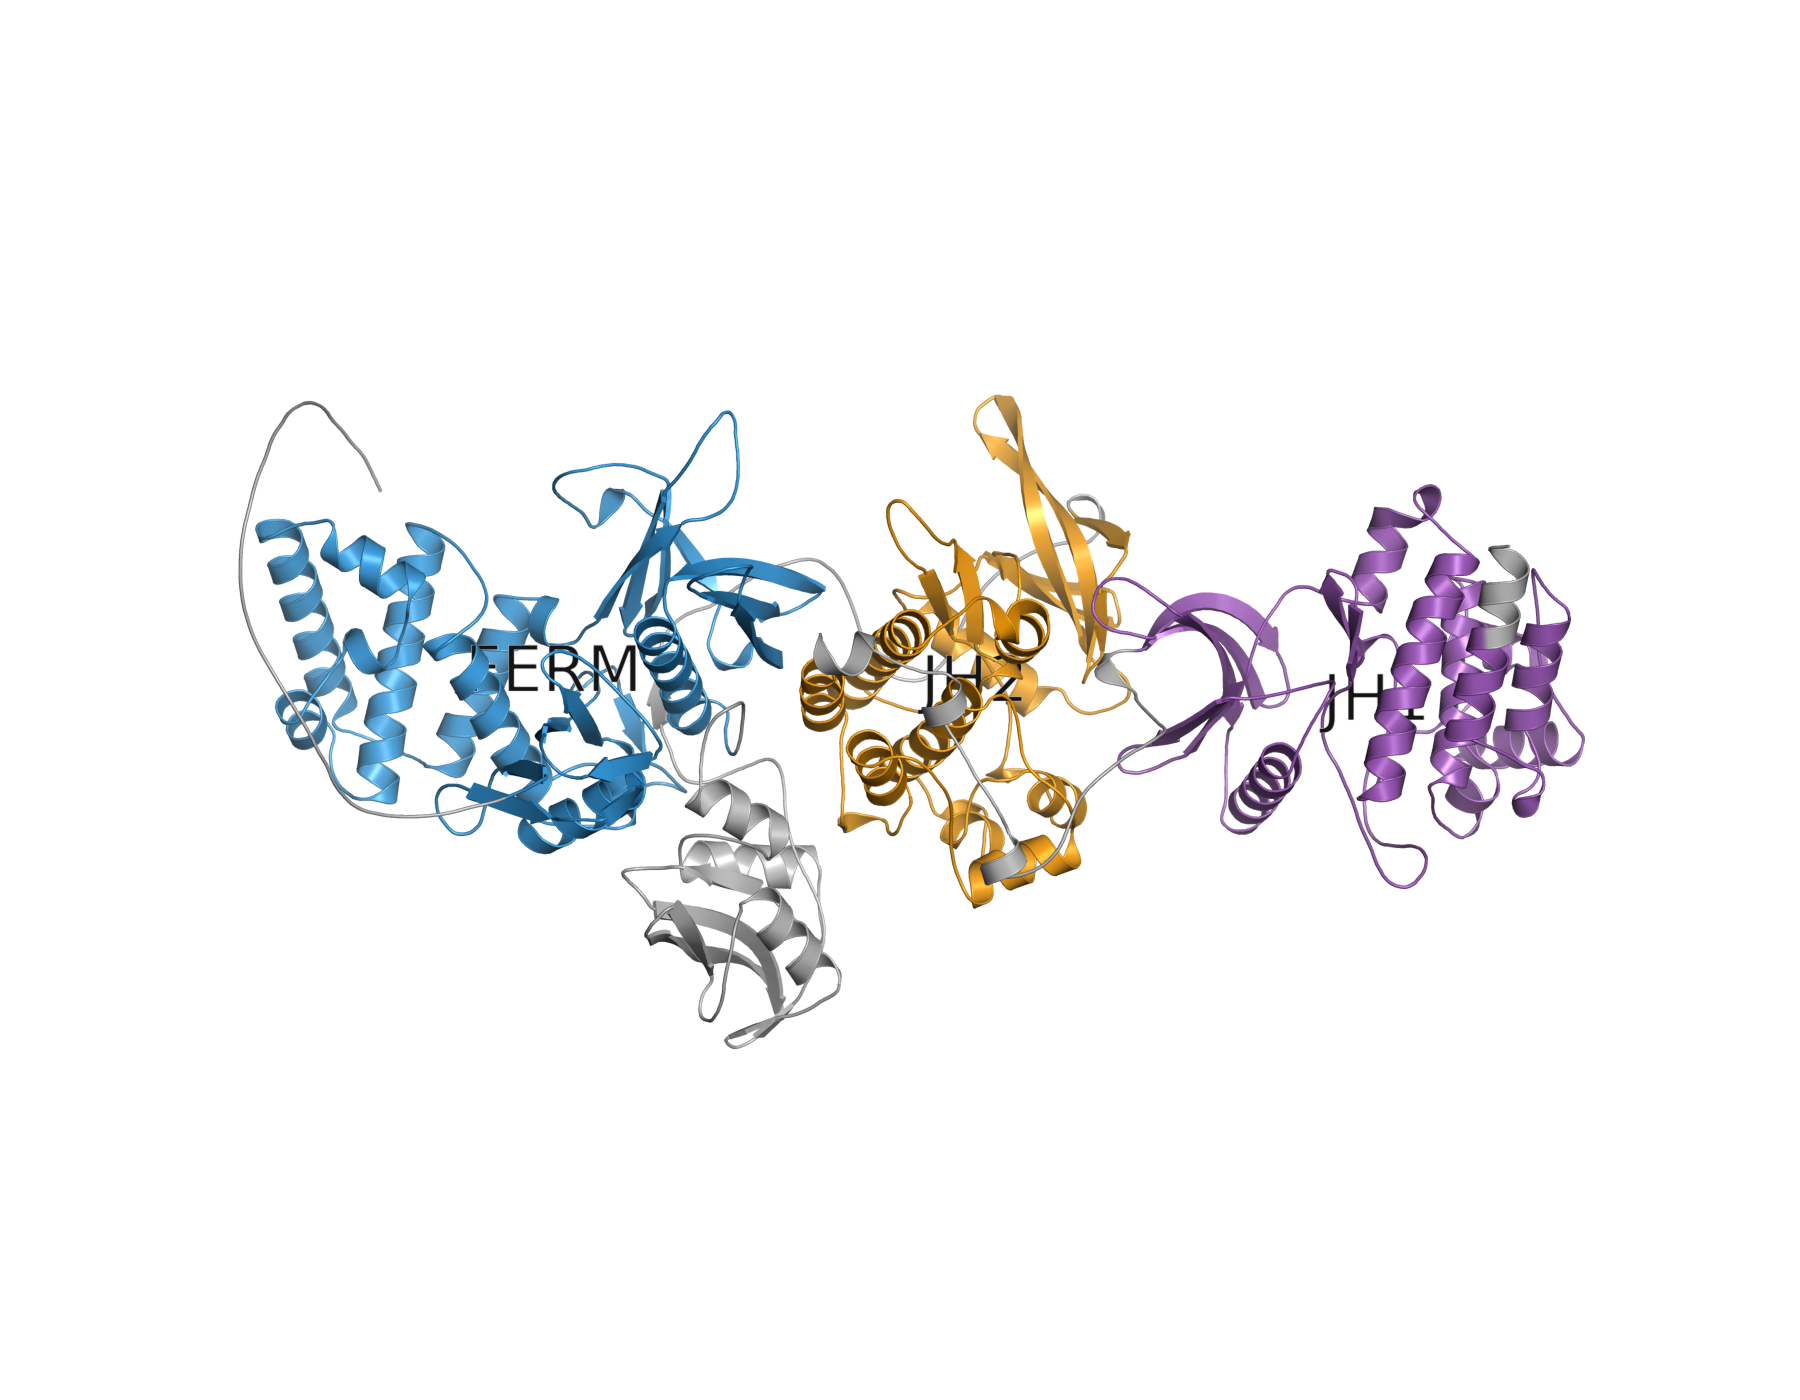


AlphaFold JAK2 — JH2 and JH1


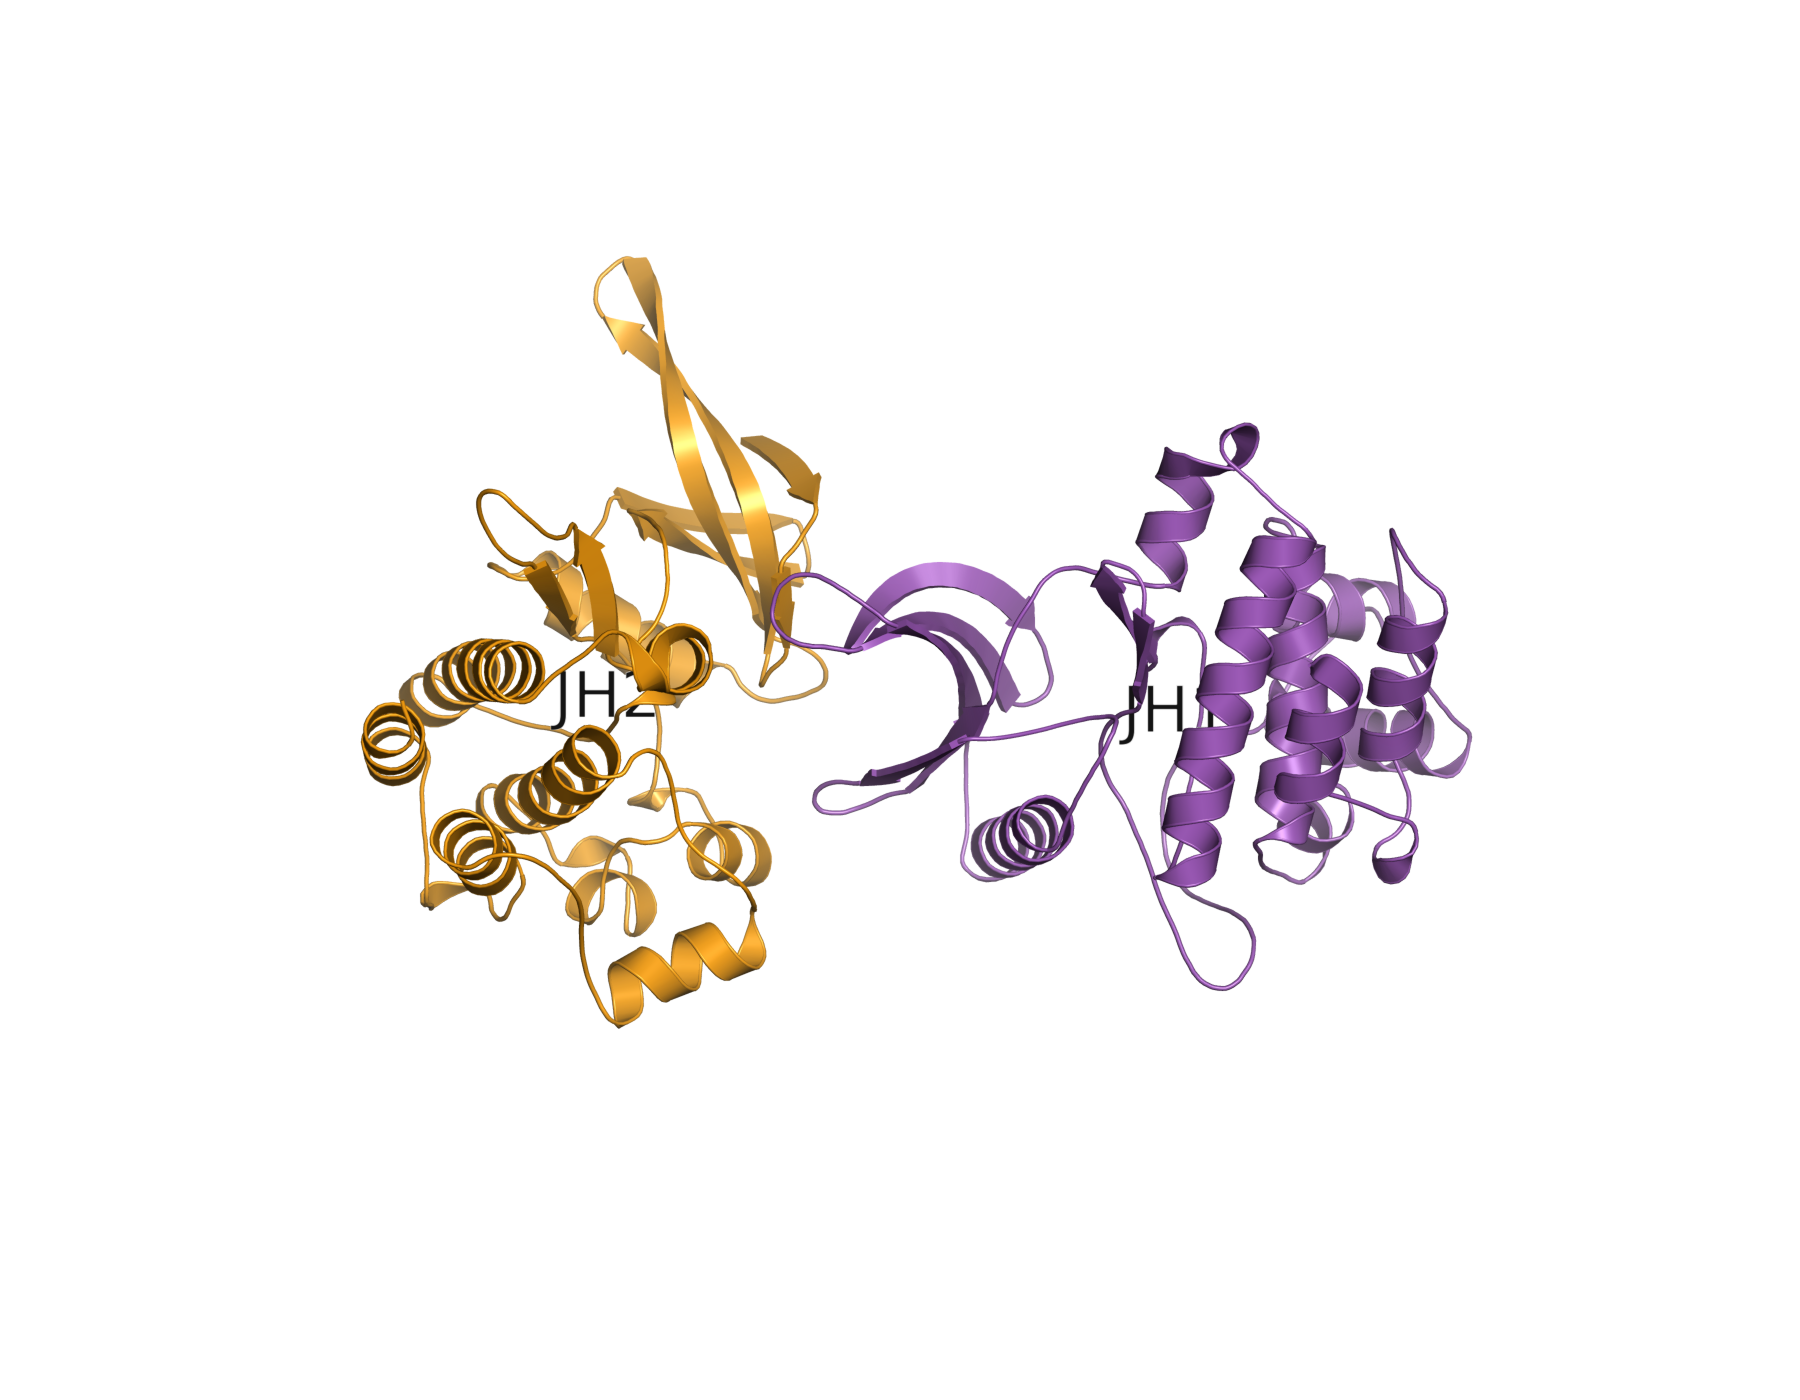


Shan JAK2 — aligned to AlphaFold


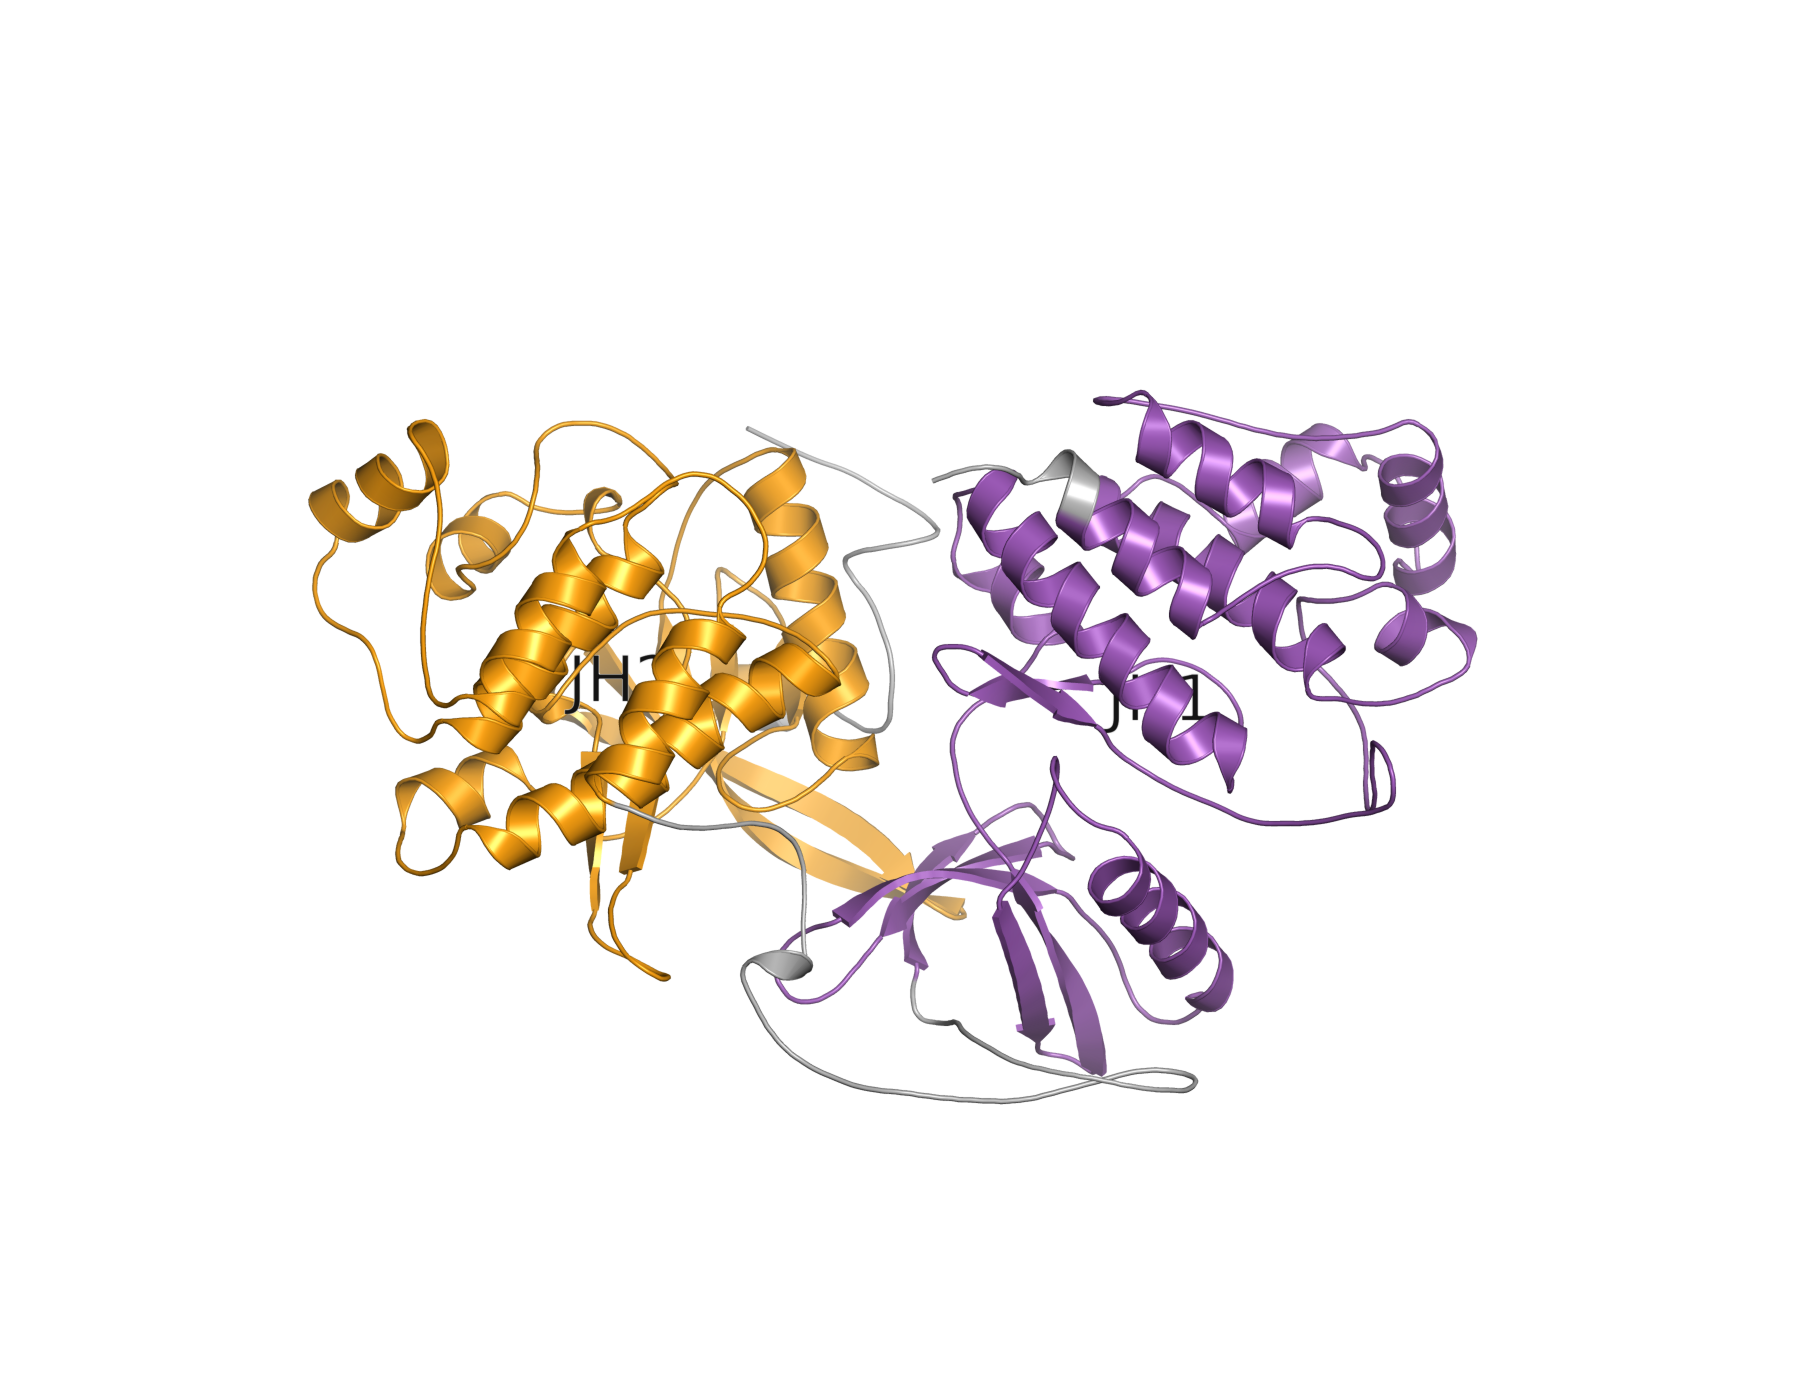

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import io
import os
import tarfile
import subprocess
from pathlib import Path

import requests
from IPython.display import display, Image

# ------------------------------------------------------------
# 1. Download micromamba to create an isolated environment
# ------------------------------------------------------------
micromamba = Path("/content/micromamba")
env_dir = Path("/content/pymol_env")

if not micromamba.exists():
    response = requests.get(
        "https://micro.mamba.pm/api/micromamba/linux-64/latest",
        timeout=180,
    )
    response.raise_for_status()

    with tarfile.open(
        fileobj=io.BytesIO(response.content), mode="r:bz2"
    ) as archive:
        binary = archive.extractfile("bin/micromamba")
        if binary is None:
            raise RuntimeError("micromamba binary not found.")
        micromamba.write_bytes(binary.read())

    micromamba.chmod(0o755)

# Prevent Colab Python settings from leaking into the new environment.
clean_env = os.environ.copy()
for key in ("PYTHONPATH", "PYTHONHOME"):
    clean_env.pop(key, None)

clean_env["MAMBA_ROOT_PREFIX"] = "/content/mamba_root"

# ------------------------------------------------------------
# 2. Install compatible Python and PyMOL
# ------------------------------------------------------------
env_python = env_dir / "bin/python"

if not env_python.exists():
    subprocess.run(
        [
            str(micromamba),
            "create", "-y",
            "-p", str(env_dir),
            "-c", "conda-forge",
            "python=3.11",
            "pymol-open-source",
        ],
        env=clean_env,
        check=True,
    )

# ------------------------------------------------------------
# 3. Write the rendering script with the configuration embedded
#    Reuses render_script, config_path and jobs from earlier.
# ------------------------------------------------------------
fixed_script = render_script.replace(
    'jobs = json.load(open(sys.argv[1]))',
    f'jobs = json.load(open({str(config_path)!r}))',
)

script_path = PNG_DIR / "render_jak2_compatible.py"
script_path.write_text(fixed_script)

for job in jobs:
    Path(job["png"]).unlink(missing_ok=True)

# ------------------------------------------------------------
# 4. Render using the isolated PyMOL installation
# ------------------------------------------------------------
command = [
    str(micromamba),
    "run", "-p", str(env_dir),
    "python", "-m", "pymol",
    "-cq", "-r", str(script_path),
]

result = subprocess.run(
    command,
    env=clean_env,
    capture_output=True,
    text=True,
)

missing = [
    job["png"] for job in jobs
    if not Path(job["png"]).exists()
    or Path(job["png"]).stat().st_size == 0
]

if missing:
    print("Exit code:", result.returncode)
    print("\nSTDOUT:\n", result.stdout)
    print("\nSTDERR:\n", result.stderr)
    raise RuntimeError("Rendering failed; see the detailed output above.")

# ------------------------------------------------------------
# 5. Display and download PNGs
# ------------------------------------------------------------
for job in jobs:
    print("\n" + job["title"])
    display(Image(filename=job["png"], width=900))

import zipfile
from google.colab import files

zip_path = PNG_DIR / "JAK2_cartoon_PNGs.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for job in jobs:
        archive.write(job["png"], arcname=Path(job["png"]).name)

files.download(str(zip_path))

In [9]:
import numpy as np
import pandas as pd
from Bio.SVDSuperimposer import SVDSuperimposer
from IPython.display import display

# Requires af, shan and domain_ranges from the previous comparison cell.
# Residue mappings use full-length UniProt numbering.

def positions_in_domain(domain):
    return {
        position
        for start, end in domain_ranges[domain]
        for position in range(start, end + 1)
    }


# Use only corresponding residues with Cα atoms in both models.
common_positions = {
    position
    for position in set(af["mapping"]) & set(shan["mapping"])
    if "CA" in af["mapping"][position]
    and "CA" in shan["mapping"][position]
}

evaluation_positions = {
    "JH1": sorted(common_positions & positions_in_domain("JH1")),
    "JH2": sorted(common_positions & positions_in_domain("JH2")),
}
evaluation_positions["JH1 + JH2"] = sorted(
    set(evaluation_positions["JH1"])
    | set(evaluation_positions["JH2"])
)

for domain in ("JH1", "JH2"):
    expected = len(positions_in_domain(domain))
    available = len(evaluation_positions[domain])
    print(f"{domain}: {available}/{expected} common Cα pairs")


def get_coordinates(model, positions):
    return np.array(
        [model["mapping"][p]["CA"].coord for p in positions],
        dtype=np.float64,
    )


def rmsd_metrics(reference_xyz, transformed_xyz):
    squared_distances = np.sum(
        (transformed_xyz - reference_xyz) ** 2,
        axis=1,
    )

    n_pairs = len(squared_distances)
    if n_pairs == 0:
        raise ValueError("No corresponding Cα pairs.")

    # Retain ceil(0.95*N) pairs with the smallest residual distances.
    n_keep = int(np.ceil(0.95 * n_pairs))
    closest = np.sort(squared_distances)[:n_keep]

    return {
        "CA_pairs": n_pairs,
        "RMSD_A": float(np.sqrt(squared_distances.mean())),
        "RMSD95_A": float(np.sqrt(closest.mean())),
        "Pairs_used_RMSD95": n_keep,
    }


rows = []
transformations = {}

for alignment_name, fit_positions in evaluation_positions.items():
    if len(fit_positions) < 3:
        raise ValueError(
            f"Too few Cα pairs for alignment by {alignment_name}."
        )

    reference_fit = get_coordinates(af, fit_positions)
    moving_fit = get_coordinates(shan, fit_positions)

    # Find the optimal rigid transformation: Shan → AlphaFold.
    superimposer = SVDSuperimposer()
    superimposer.set(reference_fit, moving_fit)
    superimposer.run()
    rotation, translation = superimposer.get_rotran()

    transformations[alignment_name] = {
        "rotation": rotation,
        "translation": translation,
    }

    # Evaluate each domain and the combined region under this SAME fit.
    for evaluation_name, positions in evaluation_positions.items():
        reference_xyz = get_coordinates(af, positions)
        moving_xyz = get_coordinates(shan, positions)

        transformed_xyz = moving_xyz @ rotation + translation
        metrics = rmsd_metrics(reference_xyz, transformed_xyz)

        rows.append({
            "Aligned_by": alignment_name,
            "Evaluated_on": evaluation_name,
            **metrics,
        })

results_rmsd = pd.DataFrame(rows)

print("\nAlphaFold vs Shan JAK2 — all distances in Å:")
display(results_rmsd.round(3))

print("\nSummary: each region evaluated after its own alignment")
summary = results_rmsd[
    results_rmsd["Aligned_by"] == results_rmsd["Evaluated_on"]
]
display(summary.round(3))

print("\nRMSD95 keeps the closest 95% of pairs AFTER alignment.")
print("No additional refitting is performed after removing outliers.")

JH1: 276/276 common Cα pairs
JH2: 265/265 common Cα pairs

AlphaFold vs Shan JAK2 — all distances in Å:


,Aligned_by,Evaluated_on,CA_pairs,RMSD_A,RMSD95_A,Pairs_used_RMSD95
0,JH1,JH1,276,3.067,2.550,263
1,JH1,JH2,265,51.662,49.529,252
2,JH1,JH1 + JH2,541,36.224,32.348,514
3,JH2,JH1,276,83.482,81.700,263
4,JH2,JH2,265,4.630,3.856,252
5,JH2,JH1 + JH2,541,59.716,55.754,514
6,JH1 + JH2,JH1,276,16.331,15.318,263
7,JH1 + JH2,JH2,265,27.192,25.721,252
8,JH1 + JH2,JH1 + JH2,541,22.321,20.436,514



Summary: each region evaluated after its own alignment


,Aligned_by,Evaluated_on,CA_pairs,RMSD_A,RMSD95_A,Pairs_used_RMSD95
0,JH1,JH1,276,3.067,2.550,263
4,JH2,JH2,265,4.630,3.856,252
8,JH1 + JH2,JH1 + JH2,541,22.321,20.436,514



RMSD95 keeps the closest 95% of pairs AFTER alignment.
No additional refitting is performed after removing outliers.


For the reference



| RMSD | Rough interpretation |
|---|---|
| **<0.5 Å** | Extremely close |
| **0.5–1 Å** | Very close |
| **1–2 Å** | Good overall agreement; some local differences |
| **2–3 Å** | Noticeable structural differences |
| **3–5 Å** | Substantial differences |
| **>5 Å** | Large differences; inspect alignment, coverage and conformation |


| Comparison | Median RMSD |
|---|---:|
| Different experimental structures of the same protein | **≈0.6 Å** |
| AlphaFold models versus experimental structures | **≈1 Å** |
| High-confidence regions of AlphaFold versus experiment | **≈0.6 Å** |


In physical size, each folded kinase domain is roughly 30–50 Å across (3–5 nm), depending on the direction measured. So a 5 Å change in centroid separation is about 10–17% of a domain’s width.

All distances in Å; RMSD95 retains the closest 95% without refitting.


,Aligned_by,Evaluated_on,CA_pairs,RMSD_A,RMSD95_A,Pairs_RMSD95
0,JH1,JH1,276,3.067,2.550,263
1,JH1,JH2,265,51.662,49.529,252
2,JH1,Both,541,36.224,32.348,514
3,JH2,JH1,276,83.482,81.700,263
4,JH2,JH2,265,4.630,3.856,252
5,JH2,Both,541,59.716,55.754,514
6,Both,JH1,276,16.331,15.318,263
7,Both,JH2,265,27.192,25.721,252
8,Both,Both,541,22.321,20.436,514



JH2: orange | JH1: purple
AlphaFold: opaque | Shan: transparent

Aligned by JH1 — fit RMSD: 3.067 Å; fit RMSD95: 2.550 Å


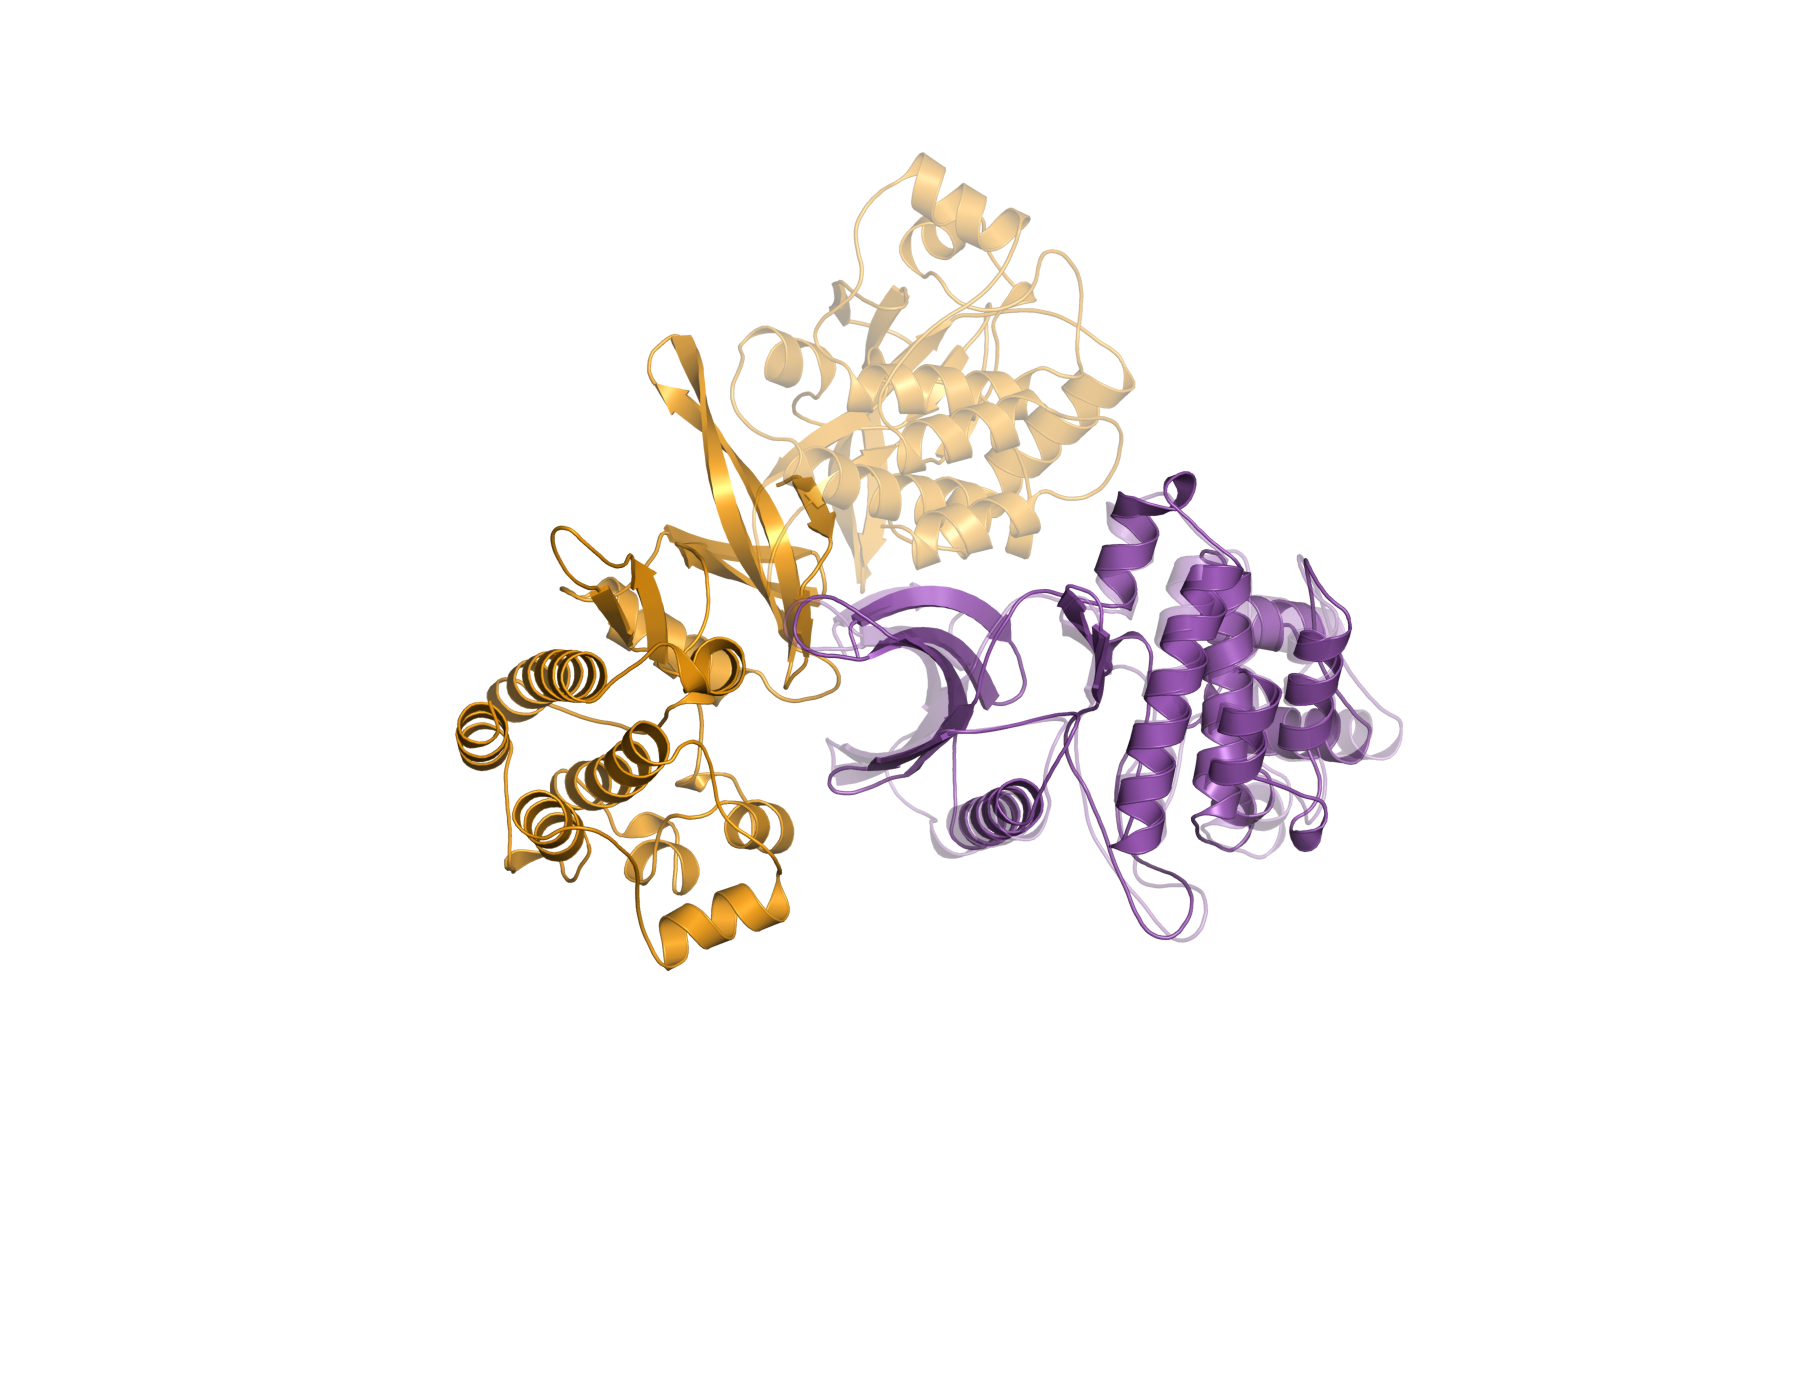


Aligned by JH2 — fit RMSD: 4.630 Å; fit RMSD95: 3.856 Å


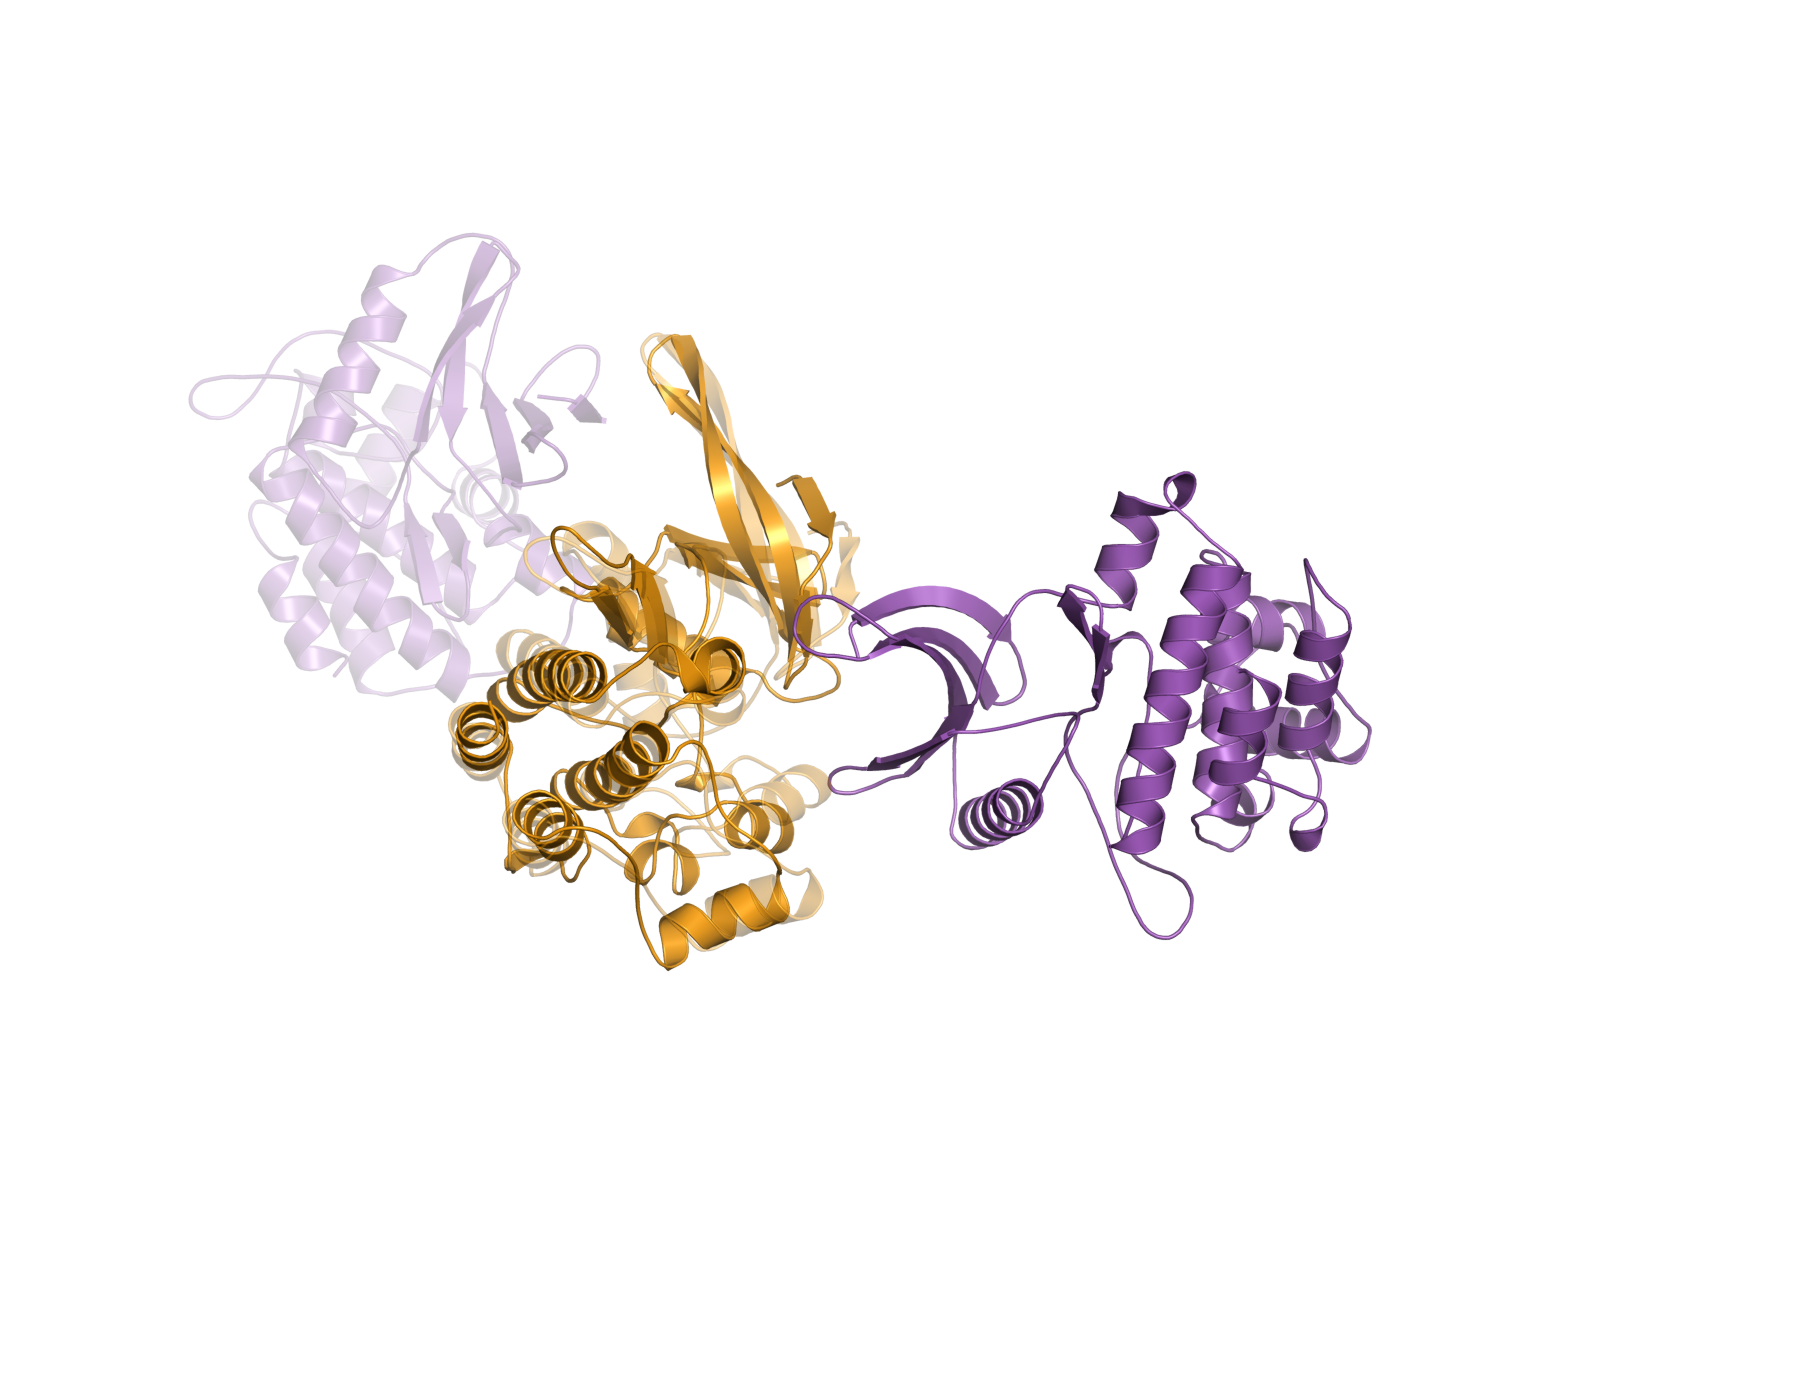


Aligned by Both — fit RMSD: 22.321 Å; fit RMSD95: 20.436 Å


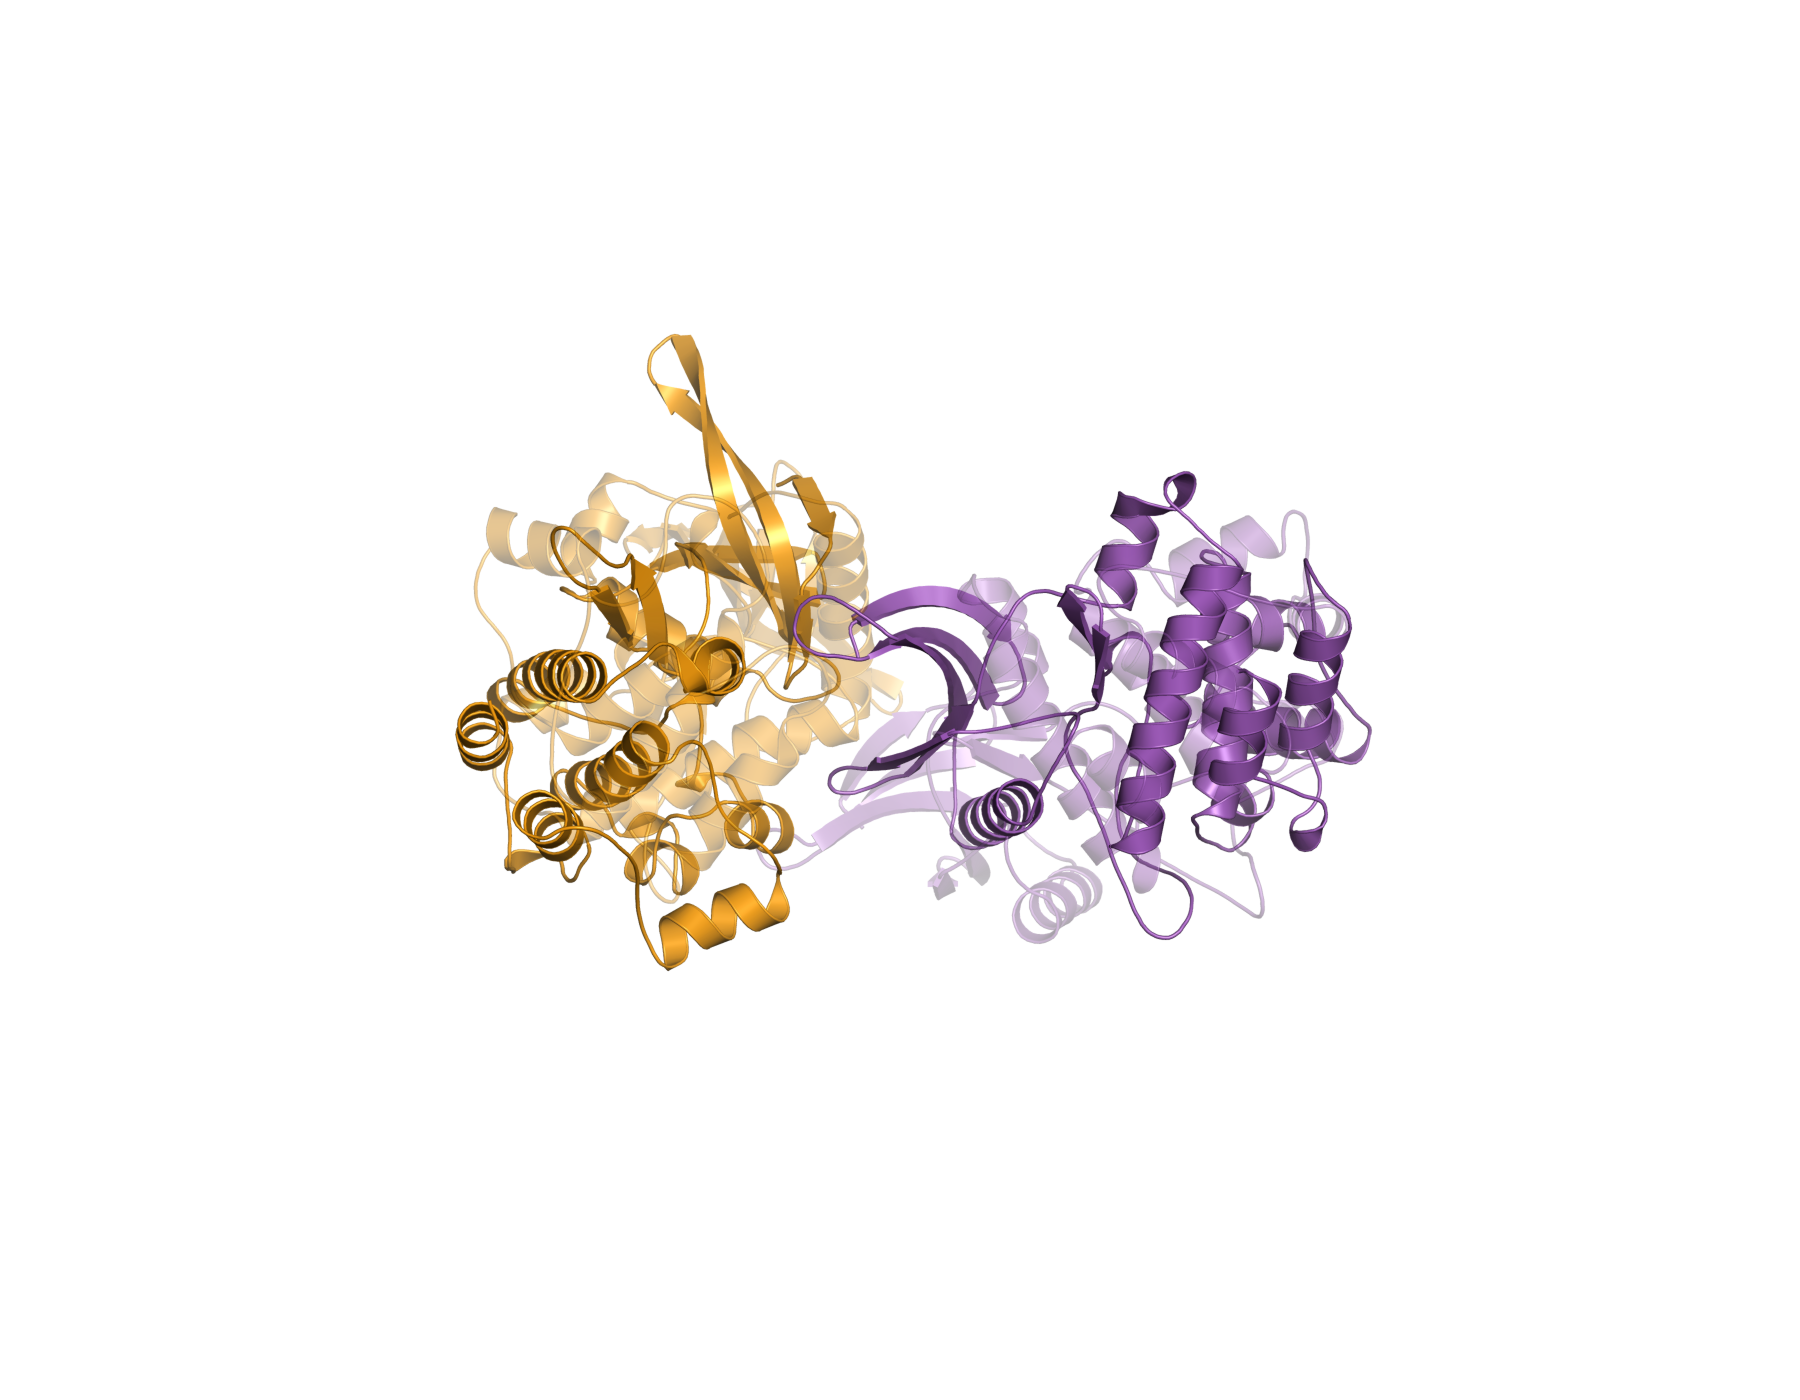

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
%pip install -q numpy pandas biopython requests

import io
import os
import json
import tarfile
import subprocess
import zipfile
from pathlib import Path

import requests
import numpy as np
import pandas as pd
from Bio.PDB import PDBIO, Select
from Bio.SVDSuperimposer import SVDSuperimposer
from IPython.display import display, Image

PLOT_DIR = Path("/content/JAK2_alignment_PNG")
PLOT_DIR.mkdir(exist_ok=True)


# ============================================================
# 1. Corresponding Cα coordinates and domain selections
# ============================================================
def domain_positions(domain):
    return {
        p
        for start, end in domain_ranges[domain]
        for p in range(start, end + 1)
    }


common = {
    p for p in set(af["mapping"]) & set(shan["mapping"])
    if "CA" in af["mapping"][p] and "CA" in shan["mapping"][p]
}

regions = {
    "JH1": sorted(common & domain_positions("JH1")),
    "JH2": sorted(common & domain_positions("JH2")),
}
regions["Both"] = sorted(set(regions["JH1"]) | set(regions["JH2"]))

if any(len(positions) < 3 for positions in regions.values()):
    raise ValueError("Insufficient corresponding Cα atoms.")

# Take copies: none of the fits will modify the original coordinates.
all_positions = regions["Both"]
af_xyz = np.array(
    [af["mapping"][p]["CA"].coord for p in all_positions],
    dtype=np.float64,
)
shan_xyz = np.array(
    [shan["mapping"][p]["CA"].coord for p in all_positions],
    dtype=np.float64,
)
index_by_position = {p: i for i, p in enumerate(all_positions)}


def metrics(reference, moving):
    squared = np.sum((moving - reference) ** 2, axis=1)
    n95 = int(np.ceil(0.95 * len(squared)))
    return {
        "CA_pairs": len(squared),
        "RMSD_A": float(np.sqrt(squared.mean())),
        "RMSD95_A": float(np.sqrt(np.sort(squared)[:n95].mean())),
        "Pairs_RMSD95": n95,
    }


# ============================================================
# 2. Export corresponding JH1/JH2 residues to normalized PDBs
#    Renumber using UniProt positions, preserving all atoms.
# ============================================================
class OnlyMappedResidues(Select):
    def __init__(self, selected_ids):
        self.selected_ids = selected_ids

    def accept_residue(self, residue):
        return id(residue) in self.selected_ids


def export_domain_pdb(model):
    # Copy the selected chain before transforming or renumbering it.
    original_chain = next(iter(model["mapping"].values())).get_parent()
    chain_copy = original_chain.copy()

    selected_original_ids = {
        model["mapping"][p].id: p for p in all_positions
    }

    kept = []
    for residue in list(chain_copy):
        original_id = residue.id
        if original_id not in selected_original_ids:
            chain_copy.detach_child(original_id)
        else:
            kept.append((residue, selected_original_ids[original_id]))

    # Detach before renumbering to avoid residue-ID collisions.
    for residue, _ in kept:
        chain_copy.detach_child(residue.id)

    for residue, position in kept:
        residue.id = (" ", position, " ")
        chain_copy.add(residue)

    writer = PDBIO()
    writer.set_structure(chain_copy)
    buffer = io.StringIO()
    writer.save(buffer)
    return buffer.getvalue()


af_fragment_text = export_domain_pdb(af)
shan_fragment_text = export_domain_pdb(shan)

af_fragment_path = PLOT_DIR / "AF_JAK2_domains.pdb"
af_fragment_path.write_text(af_fragment_text)


def transform_pdb_text(pdb_text, rotation, translation):
    """Apply the Cα-derived fit to every atom in the exported fragment."""
    lines = []

    for line in pdb_text.splitlines():
        if line.startswith(("ATOM  ", "HETATM")):
            xyz = np.array([
                float(line[30:38]),
                float(line[38:46]),
                float(line[46:54]),
            ])
            xyz = xyz @ rotation + translation
            line = (
                line[:30]
                + f"{xyz[0]:8.3f}{xyz[1]:8.3f}{xyz[2]:8.3f}"
                + line[54:]
            )
        lines.append(line)

    return "\n".join(lines) + "\n"


rows = []
jobs = []

for fit_name, fit_positions in regions.items():
    fit_indices = [index_by_position[p] for p in fit_positions]

    fit = SVDSuperimposer()
    fit.set(af_xyz[fit_indices], shan_xyz[fit_indices])
    fit.run()
    rotation, translation = fit.get_rotran()

    transformed = shan_xyz @ rotation + translation

    for evaluation_name, positions in regions.items():
        indices = [index_by_position[p] for p in positions]
        rows.append({
            "Aligned_by": fit_name,
            "Evaluated_on": evaluation_name,
            **metrics(af_xyz[indices], transformed[indices]),
        })

    aligned_path = PLOT_DIR / f"Shan_aligned_by_{fit_name}.pdb"
    aligned_path.write_text(
        transform_pdb_text(shan_fragment_text, rotation, translation)
    )

    fit_metrics = metrics(
        af_xyz[fit_indices], transformed[fit_indices]
    )

    jobs.append({
        "fit": fit_name,
        "af_pdb": str(af_fragment_path),
        "shan_pdb": str(aligned_path),
        "png": str(PLOT_DIR / f"JAK2_alignment_{fit_name}.png"),
        "fit_rmsd": fit_metrics["RMSD_A"],
        "fit_rmsd95": fit_metrics["RMSD95_A"],
        "domains": {
            domain: regions[domain] for domain in ("JH1", "JH2")
        },
    })

results = pd.DataFrame(rows)

print("All distances in Å; RMSD95 retains the closest 95% without refitting.")
display(results.round(3))

results.to_csv(PLOT_DIR / "RMSD_results.csv", index=False)


# ============================================================
# 3. Install PyMOL in isolated Python 3.11
#    Compatible with Colab running Python 3.13.
# ============================================================
micromamba = Path("/content/micromamba")
env_dir = Path("/content/pymol_env")

if not micromamba.exists():
    response = requests.get(
        "https://micro.mamba.pm/api/micromamba/linux-64/latest",
        timeout=180,
    )
    response.raise_for_status()

    with tarfile.open(
        fileobj=io.BytesIO(response.content), mode="r:bz2"
    ) as archive:
        micromamba.write_bytes(
            archive.extractfile("bin/micromamba").read()
        )
    micromamba.chmod(0o755)

clean_env = os.environ.copy()
for key in ("PYTHONPATH", "PYTHONHOME"):
    clean_env.pop(key, None)
clean_env["MAMBA_ROOT_PREFIX"] = "/content/mamba_root"

if not (env_dir / "bin/python").exists():
    subprocess.run(
        [
            str(micromamba), "create", "-y",
            "-p", str(env_dir), "-c", "conda-forge",
            "python=3.11", "pymol-open-source",
        ],
        env=clean_env,
        check=True,
    )


# ============================================================
# 4. Render three overlays with the SAME camera
# ============================================================
config_path = PLOT_DIR / "render_jobs.json"
config_path.write_text(json.dumps(jobs))

render_script = """
import json
from pymol import cmd

jobs = json.load(open(CONFIG_PATH))
shared_view = None

for job in jobs:
    cmd.reinitialize()
    cmd.load(job["af_pdb"], "AF")
    cmd.load(job["shan_pdb"], "Shan")

    cmd.hide("everything", "all")
    cmd.dss("all")
    cmd.show("cartoon", "AF or Shan")

    cmd.set_color("jh2_color", [0.953, 0.612, 0.071])
    cmd.set_color("jh1_color", [0.608, 0.349, 0.714])

    for domain, color in (
        ("JH2", "jh2_color"), ("JH1", "jh1_color")
    ):
        ids = "+".join(map(str, job["domains"][domain]))
        cmd.color(color, "(AF or Shan) and resi " + ids)

    cmd.set("cartoon_transparency", 0.0, "AF")
    cmd.set("cartoon_transparency", 0.55, "Shan")
    cmd.set("cartoon_fancy_helices", 1)
    cmd.set("cartoon_flat_sheets", 1)
    cmd.set("cartoon_smooth_loops", 1)

    cmd.bg_color("white")
    cmd.set("orthoscopic", 1)
    cmd.set("ray_shadows", 0)
    cmd.set("antialias", 2)

    # Keep all PNGs in the same AlphaFold reference orientation.
    if shared_view is None:
        cmd.orient("AF")
        cmd.zoom("AF", buffer=20)
        shared_view = cmd.get_view()
    else:
        cmd.set_view(shared_view)

    cmd.png(
        job["png"], width=1800, height=1400,
        dpi=200, ray=1, quiet=0
    )

cmd.quit()
""".replace("CONFIG_PATH", repr(str(config_path)))

script_path = PLOT_DIR / "render_alignments.py"
script_path.write_text(render_script)

for job in jobs:
    Path(job["png"]).unlink(missing_ok=True)

result = subprocess.run(
    [
        str(micromamba), "run", "-p", str(env_dir),
        "python", "-m", "pymol",
        "-cq", "-r", str(script_path),
    ],
    env=clean_env,
    capture_output=True,
    text=True,
)

missing = [
    job["png"] for job in jobs
    if not Path(job["png"]).exists()
    or Path(job["png"]).stat().st_size == 0
]

if missing:
    print("Exit code:", result.returncode)
    print("STDOUT:", result.stdout)
    print("STDERR:", result.stderr)
    raise RuntimeError("PNG rendering failed; see output above.")


# ============================================================
# 5. Display and download
# ============================================================
print("\nJH2: orange | JH1: purple")
print("AlphaFold: opaque | Shan: transparent")

for job in jobs:
    print(
        f"\nAligned by {job['fit']} — "
        f"fit RMSD: {job['fit_rmsd']:.3f} Å; "
        f"fit RMSD95: {job['fit_rmsd95']:.3f} Å"
    )
    display(Image(filename=job["png"], width=900))

zip_path = PLOT_DIR / "JAK2_alignments.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for job in jobs:
        archive.write(job["png"], arcname=Path(job["png"]).name)
    archive.write(
        PLOT_DIR / "RMSD_results.csv",
        arcname="RMSD_results.csv",
    )

from google.colab import files
files.download(str(zip_path))

For the reference



| RMSD | Rough interpretation |
|---|---|
| **<0.5 Å** | Extremely close |
| **0.5–1 Å** | Very close |
| **1–2 Å** | Good overall agreement; some local differences |
| **2–3 Å** | Noticeable structural differences |
| **3–5 Å** | Substantial differences |
| **>5 Å** | Large differences; inspect alignment, coverage and conformation |


| Comparison | Median RMSD |
|---|---:|
| Different experimental structures of the same protein | **≈0.6 Å** |
| AlphaFold models versus experimental structures | **≈1 Å** |
| High-confidence regions of AlphaFold versus experiment | **≈0.6 Å** |


In physical size, each folded kinase domain is roughly 30–50 Å across (3–5 nm), depending on the direction measured. So a 5 Å change in centroid separation is about 10–17% of a domain’s width.